<a href="https://colab.research.google.com/github/chandupradeep18/Python_pandas_projects/blob/main/Analyze_Movie_Ratings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas matplotlib

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
links=pd.read_csv('/content/drive/MyDrive/ClaudeResponse/links.csv')
movies=pd.read_csv('/content/drive/MyDrive/ClaudeResponse/movies.csv')
ratings=pd.read_csv('/content/drive/MyDrive/ClaudeResponse/ratings.csv')
tags=pd.read_csv('/content/drive/MyDrive/ClaudeResponse/tags.csv')

In [ ]:
print(links.shape,movies.shape,ratings.shape,tags.shape)
print("Link Colums :",links.columns.to_list())
print(links.dtypes,'\n')
print("Movies Colums :",movies.columns.to_list())
print(movies.dtypes,'\n')
print("Ratings Colums :",ratings.columns.to_list())
print(ratings.dtypes,'\n')
print("Tags Colums :",tags.columns.to_list())
print(tags.dtypes,'\n')

In [ ]:
print(f"{links.isnull().sum()}")
print(f"{movies.isnull().sum()}")
print(f"{ratings.isnull().sum()}")
print(f"{tags.isnull().sum()}")

In [ ]:
print(f"{links.duplicated().sum()}")
print(f"{movies.duplicated().sum()}")
print(f"{ratings.duplicated().sum()}")
print(f"{tags.duplicated().sum()}")

In [ ]:
print(movies.sample(4))
print(ratings.sample(4))
print(links.sample(4))
print(tags.sample(4))

      movieId                      title    genres
7206    72733            Invictus (2009)     Drama
9275   157312            The Boss (2016)    Comedy
9187   149590            Standoff (2016)  Thriller
987      1288  This Is Spinal Tap (1984)    Comedy
       userId  movieId  rating   timestamp
10999      68     4487     4.0  1269123622
30357     212    31658     4.0  1490115674
33374     226     4676     2.0  1096421496
60424     391      232     2.0  1032389024
      movieId  imdbId   tmdbId
1395     1913   73540  11020.0
6028    39183  388795    142.0
935      1235   67185    343.0
705       923   33467     15.0
      userId  movieId             tag   timestamp
956      424   106100       uplifting  1457845933
2844     537    80489         romance  1424139421
735      424      589     nuclear war  1457844861
2218     474     6948  music business  1138039867


In [ ]:
ratings_clean=ratings.copy()
ratings_clean['Count Rating']=ratings['rating']
avg_rating=ratings_clean.groupby('movieId').agg({'rating':'mean','Count Rating':'count'}).sort_values(['rating','Count Rating'],ascending=False).head(10).reset_index()
avg_rating.rename(columns={'rating':'Avg Rating','Count Rating':'Total Rating'},inplace=True)
movies_copy=movies.copy()
avg_per_movie_rating=pd.merge(movies_copy,avg_rating,on='movieId',how='right')
avg_per_movie_rating

,movieId,title,genres,Avg Rating,Total Rating
0,53,Lamerica (1994),Adventure|Drama,5.0,2
1,99,Heidi Fleiss: Hollywood Madam (1995),Documentary,5.0,2
2,1151,Lesson Faust (1994),Animation|Comedy|Drama|Fantasy,5.0,2
3,3473,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,Comedy,5.0,2
4,6442,Belle époque (1992),Comedy|Romance,5.0,2
5,6818,Come and See (Idi i smotri) (1985),Drama|War,5.0,2
6,78836,Enter the Void (2009),Drama,5.0,2
7,148,"Awfully Big Adventure, An (1995)",Drama,5.0,1
8,467,Live Nude Girls (1995),Comedy,5.0,1
9,495,In the Realm of the Senses (Ai no corrida) (1976),Drama,5.0,1


In [ ]:
print("\n=== TOP 10 MOVIES (50+ RATINGS) ===")
movie_high_count_rating=ratings_clean.groupby('movieId')["rating"].agg(['mean','count'])
movie_high_count_rating.columns=['Avg Rating','Total Rating']
movie_high_count_rating=movie_high_count_rating[movie_high_count_rating['Total Rating']>=50].sort_values('Avg Rating',ascending=False).head(10).reset_index()
movies_copy2=movies.copy()
movies_copy2=pd.merge(movies_copy2,movie_high_count_rating,on='movieId',how='inner')
movies_copy2


=== TOP 10 MOVIES (50+ RATINGS) ===


,movieId,title,genres,Avg Rating,Total Rating
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429022,317
1,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.268041,97
2,858,"Godfather, The (1972)",Crime|Drama,4.289062,192
3,904,Rear Window (1954),Mystery|Thriller,4.261905,84
4,912,Casablanca (1942),Drama|Romance,4.240000,100
5,1213,Goodfellas (1990),Crime|Drama,4.250000,126
6,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.259690,129
7,1276,Cool Hand Luke (1967),Drama,4.271930,57
8,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.272936,218
9,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.252336,107


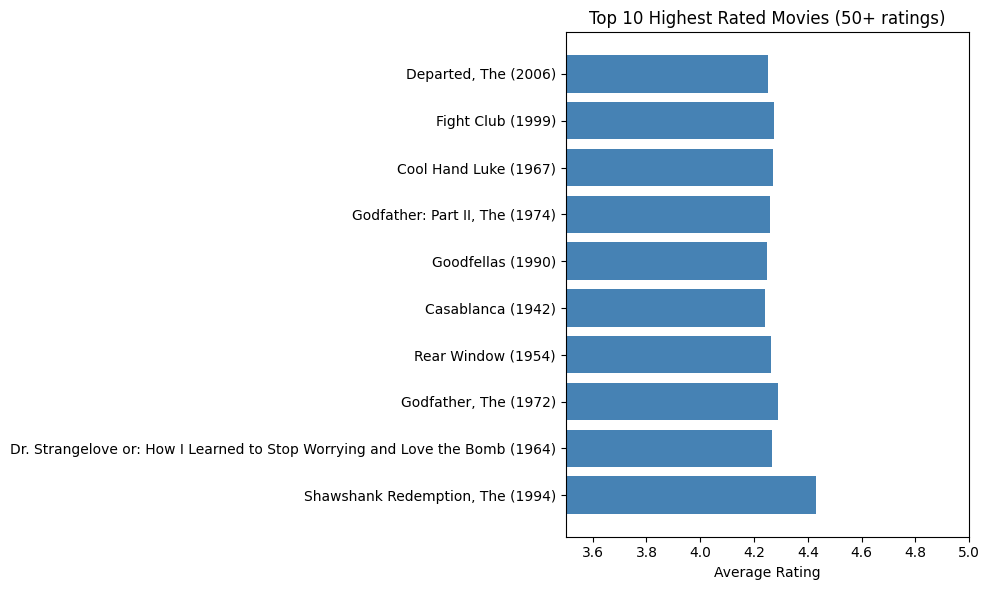

In [ ]:
# Visualization 1: Top movies bar chart
plt.figure(figsize=(10, 6))
plt.barh(movies_copy2["title"], movies_copy2["Avg Rating"], color="steelblue")
plt.xlabel("Average Rating")
plt.title("Top 10 Highest Rated Movies (50+ ratings)")
plt.xlim(3.5, 5.0)
plt.tight_layout()
plt.savefig("top_movies.png")
plt.show()

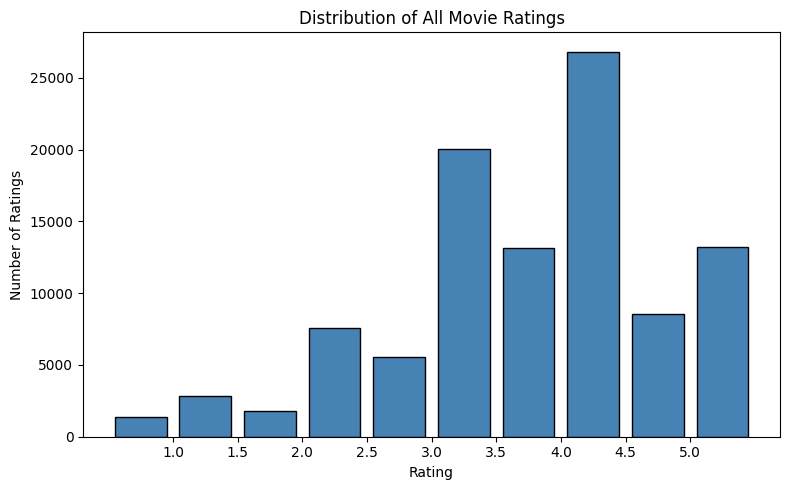

In [ ]:
# Visualization 2: Rating distribution histogram
plt.figure(figsize=(8, 5))
plt.hist(ratings["rating"], bins=[0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5],
         edgecolor="black", color="steelblue", rwidth=0.8)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Distribution of All Movie Ratings")
plt.xticks([1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5])
plt.tight_layout()
plt.savefig("rating_distribution.png")
plt.show()

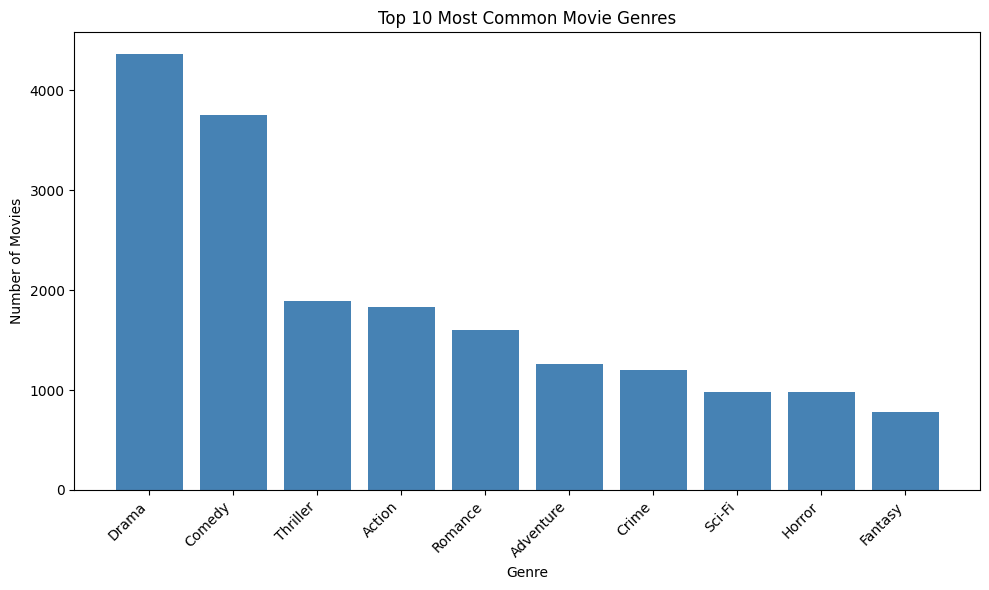


Analysis complete! Charts saved as PNG files.


In [ ]:
# Visualization 3: Genre popularity
genres_expanded = movies["genres"].str.split("|").explode()
genre_counts = genres_expanded.value_counts().head(10)

plt.figure(figsize=(10, 6))
plt.bar(genre_counts.index, genre_counts.values, color="steelblue")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.title("Top 10 Most Common Movie Genres")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("genre_popularity.png")
plt.show()

print("\nAnalysis complete! Charts saved as PNG files.")

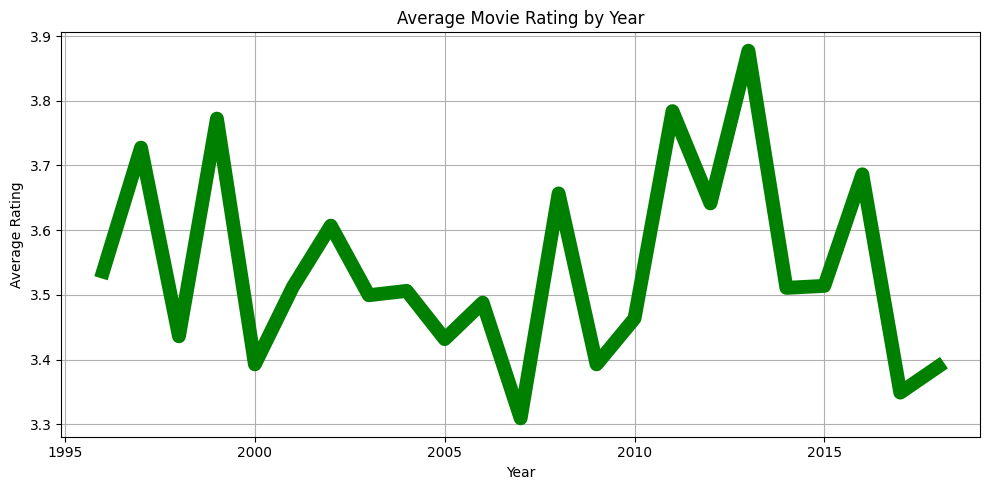


Analysis complete! All charts saved as PNG files.


In [ ]:
ratings['datetime']=pd.to_datetime(ratings['timestamp'],unit='s')
ratings['year']=ratings['datetime'].dt.year
yearly_avg=ratings.groupby('year')['rating'].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o", color="green", linewidth=10)
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.title("Average Movie Rating by Year")
plt.grid(True, alpha=1.0)
plt.tight_layout()
plt.savefig("ratings_over_time.png")
plt.show()

print("\nAnalysis complete! All charts saved as PNG files.")